# Câu 4: Khảo sát sự liên quan giữa Cổng lên tàu (embarked), loại vé (pclass) với khả năng sống sót, phân biệt theo giới tính

Phần 1 – Bài 2 (trang 15–17): Yêu cầu lập trình trên dữ liệu Titanic

In [1]:
SV = "Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT"
DATA = "../../data/"  # thư mục chứa dữ liệu
print(SV)

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT


In [ ]:
import re
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline
pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')

### Chuẩn bị: thực hiện lại các bước của các câu trước

In [3]:
df = pd.read_csv(DATA + 'titanic.csv', dtype={'age': np.float64, 'sibsp': np.int64, 'parch': np.int64})

---
## Thực hiện yêu cầu

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT


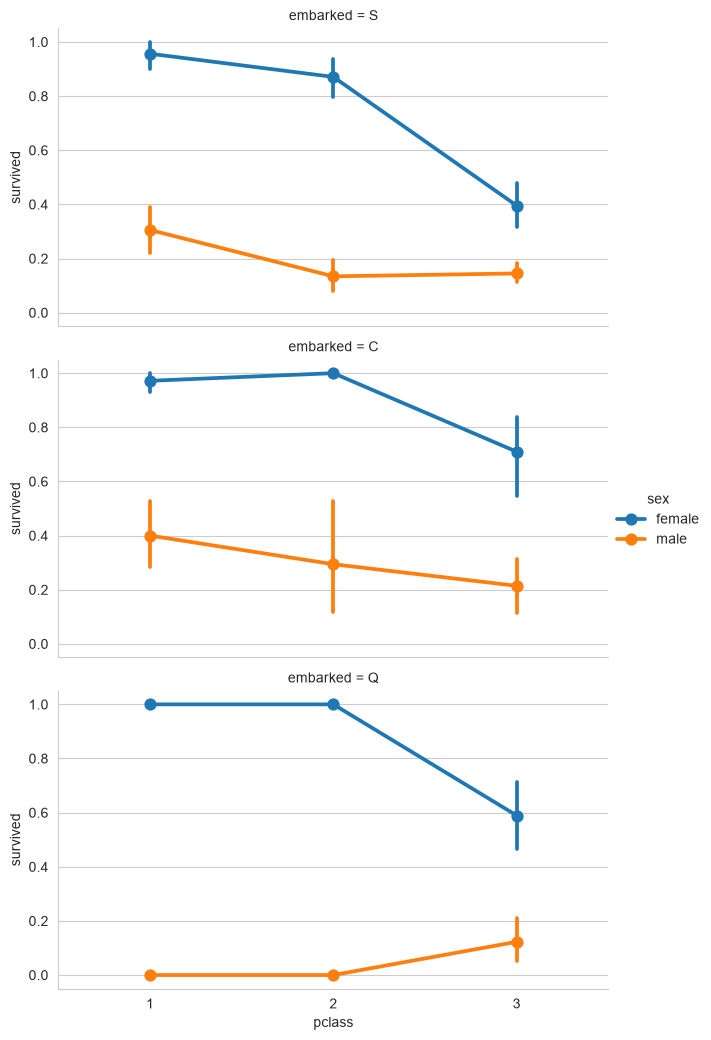

In [4]:
print(SV)
g = sns.catplot(data=df, x='pclass', y='survived', hue='sex', row='embarked',
                kind='point', height=3.5, aspect=1.8, row_order=['S', 'C', 'Q'])
plt.show()

In [5]:
pd.crosstab([df['embarked'], df['pclass']], df['sex'], values=df['survived'], aggfunc='mean').round(2)

sex              female  male
embarked pclass              
C        1         0.97  0.40
         2         1.00  0.29
         3         0.71  0.21
Q        1         1.00  0.00
         2         1.00  0.00
         3         0.59  0.12
S        1         0.96  0.31
         2         0.87  0.13
         3         0.40  0.14

Xét riêng loại vé với khả năng sống sót:

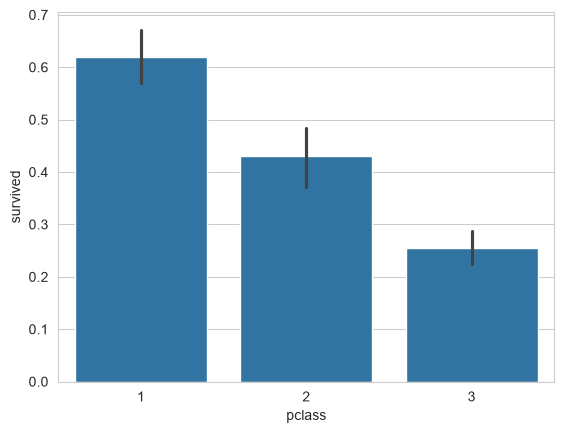

In [6]:
sns.barplot(x='pclass', y='survived', data=df)
plt.show()

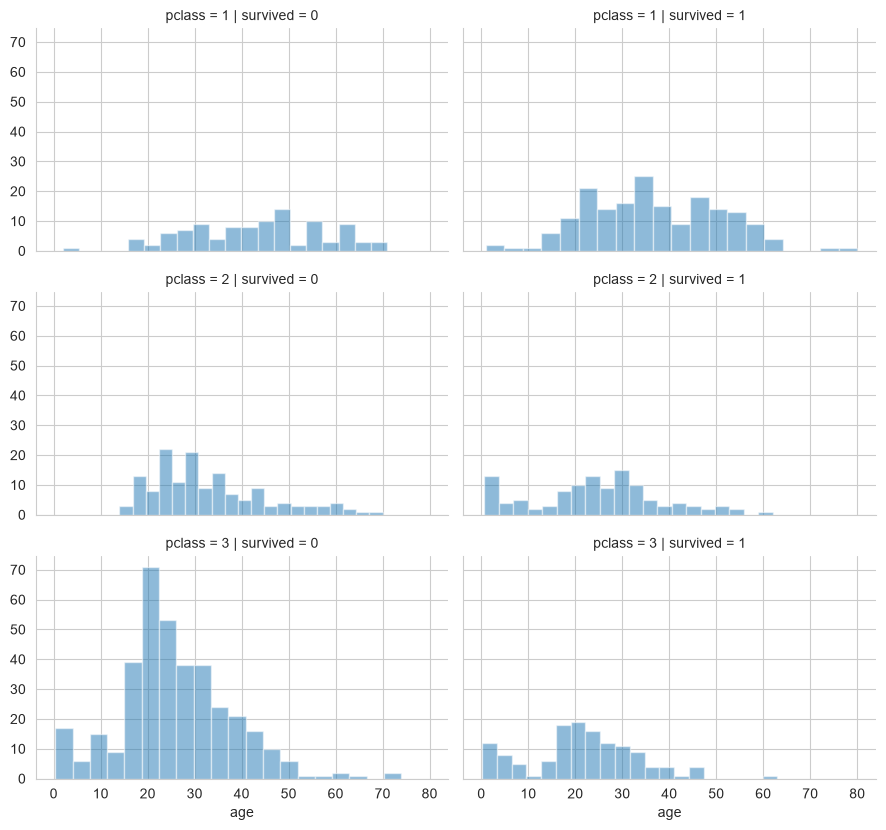

In [7]:
grid = sns.FacetGrid(df, col='survived', row='pclass', height=2.8, aspect=1.6)
grid.map(plt.hist, 'age', alpha=.5, bins=20)
plt.show()

**Nhận xét:**

- Ở cả ba cổng, nữ luôn có tỷ lệ sống sót cao hơn nam; vé hạng 1, 2 cho tỷ lệ cao hơn hạng 3.
- Nữ hạng 1, 2 gần như đều sống sót (≈87–100%); nữ hạng 3 giảm mạnh, thấp nhất ở cổng S (≈40%), cao hơn ở C (≈71%) và Q (≈59%).
- Nam lên ở cổng C có tỷ lệ sống sót cao nhất (≈21–40%), trong khi nam ở cổng Q hạng 1, 2 không ai sống sót (số lượng rất ít). Vậy cổng lên tàu có liên quan tới khả năng sống sót nhưng phụ thuộc vào giới tính và hạng vé (cổng C có nhiều khách hạng 1).
- Biểu đồ cột cho thấy rõ: tỷ lệ sống sót giảm dần theo hạng vé, hạng 1 cao nhất (≈62%), hạng 3 thấp nhất (≈26%).
- Biểu đồ phân bố tuổi theo hạng vé xác nhận: hạng 1 phần lớn sống sót, còn hạng 3 có rất nhiều người không sống sót, nhất là nhóm 18–35 tuổi.